## Penalized Regression: Ridge and LASSO

So far we have approached feature selection---that is, selection of which ${\bf X}$ variables to based our predictions on---by considering several subsets of features and comparing scores. But what if we want to consider *all* of the features? We don't necessarily want to select all the features to include in our model, because we run the risk of overfitting to the training data. But maybe we want to *consider* every feature for selection rather than just a few subsets. Penalized regression is one way of performing de facto feature selection: throw all the available features into the model and let the model fitting sort out which to include.

In [1]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score

We'll use the Ames housing data. We'll do a little cleaning first to:

- Drop a few columns that have mostly missing values
- Drop a few rows with missing values
- Drop the ID columns (row order and PID)

In [2]:
ames = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt", sep="\t")

# Get rid of columns with mostly NaN values
good_cols = ames.isna().sum() < 100
ames = ames.loc[:,good_cols]

# Drop other NAs
ames = ames.dropna()

# drop ID columns and put target in y
X = ames.drop(["SalePrice", "Order", "PID"], axis = 1)
y = ames["SalePrice"]

X

,MS SubClass,MS Zoning,Lot Area,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,...,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition
0,20,RL,31770,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,...,62,0,0,0,0,0,5,2010,WD,Normal
1,20,RH,11622,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,...,0,0,0,120,0,0,6,2010,WD,Normal
2,20,RL,14267,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,...,36,0,0,0,0,12500,6,2010,WD,Normal
3,20,RL,11160,Pave,Reg,Lvl,AllPub,Corner,Gtl,NAmes,...,0,0,0,0,0,0,4,2010,WD,Normal
4,60,RL,13830,Pave,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,...,34,0,0,0,0,0,3,2010,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,80,RL,7937,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Mitchel,...,0,0,0,0,0,0,3,2006,WD,Normal
2926,20,RL,8885,Pave,IR1,Low,AllPub,Inside,Mod,Mitchel,...,0,0,0,0,0,0,6,2006,WD,Normal
2927,85,RL,10441,Pave,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,...,32,0,0,0,0,700,7,2006,WD,Normal
2928,20,RL,10010,Pave,Reg,Lvl,AllPub,Inside,Mod,Mitchel,...,38,0,0,0,0,0,4,2006,WD,Normal


In [3]:
y

0       215000
1       105000
2       172000
3       244000
4       189900
         ...  
2925    142500
2926    131000
2927    132000
2928    170000
2929    188000
Name: SalePrice, Length: 2821, dtype: int64

Let's try a linear regression model first. We'll standardize numerical predictors and dummify categorical predictors.

In [4]:
ct = ColumnTransformer(
  [
    ("dummify",
    OneHotEncoder(sparse_output = False, handle_unknown='ignore'),
    make_column_selector(dtype_include=object)),
    ("standardize",
    StandardScaler(),
    make_column_selector(dtype_include=np.number))
  ],
  remainder = "passthrough"
).set_output(transform="pandas")

In [5]:
lr_pipeline = Pipeline(
  [("preprocessing", ct),
  ("linear_regression", LinearRegression())]
)

In [6]:
lr_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('linear_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['MS SubClass','MS Zoning','Lot Area',...,'Yr Sold','Sale Type', 'Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pa

Now let's use cross-validation to evaluate based on $R^2$.

In [7]:
cross_val_score(lr_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.88433686, 0.90316706, 0.87507511, 0.91216037, 0.82269502, 0.73890838,
       0.86879893, 0.63798647, 0.90277443, 0.90350125])

Hmmm... linear regression on all the predictors does not seem as bad as the textbook suggests, though there is considerably variability between the scores based on the different folds.

Let's add second degree polynomial terms for all numerical predictors and see what happens.

In [8]:
numeric_poly = Pipeline([
    ("polynomial_features", PolynomialFeatures(degree=2)),
    ("standardize", StandardScaler())
])

ct_poly = ColumnTransformer(
    [
        ("dummify",
         OneHotEncoder(sparse_output=False, handle_unknown="ignore"),
         make_column_selector(dtype_include=object)),

        ("numeric_poly",
         numeric_poly,
         make_column_selector(dtype_include=np.number))
    ],
    remainder="drop"
).set_output(transform="pandas")

In [9]:
poly_pipeline = Pipeline(
  [("preprocessing", ct_poly),
  ("linear_regression", LinearRegression())]
)

In [10]:
poly_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('linear_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['MS SubClass','MS Zoning','Lot Area',...,'Yr Sold','Sale Type', 'Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('numeric_poly', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically p

In [11]:
cross_val_score(poly_pipeline, X, y, cv = 10, scoring = 'r2')

array([ 0.88322049, -0.2351045 , -5.18937935,  0.53298354, -1.81034894,
        0.65934136,  0.23955858, -1.0532801 , -3.71975499,  0.31162845])

OK, now that's bad. The moral is that just throwing in all the predictors might fit the training data well but can be pretty terrible when it comes to making predictions for new observations. We want to be more selective without having to laboriously search through many possible subsets of predictors. With 67 predictors there are $2^{67}\approx 10^{20}$ possible subsets---even before we consider polynomial terms, interactions, transformations, etc---so it would be impossible to fit every possible subset.

Instead, we include all predictors but "penalize" variables that don't contribute much to the model. Before getting to the penalty we'll consider some motivating conceptual questions.

1. Consider a simple linear regression of sale price on a single variable like living area. What is the process by which the coefficient for living area is determined? How does "least squares" work? **DISCUSS**

2. Now consider a multiple of regression on living area and number of bedrooms, without standardizing variables. How does least squares work in this case? **DISCUSS**

3. If you fit the linear model, without standarizing variables, how do you interpret the coefficients for living area and number of bedrooms? What is their rough order of magnitude? Can we determine directly from the coefficients which variable the predicted prices are more sensitive to? **DISCUSS**

4. If you standardize the variables first, how would you interpret the model coefficients? How could you determine, roughly, which variable the predicted prices are more sensitive to? **DISCUSS**

5. If we want to make the predictions *less* sensitive to a particular standardized variable, what in principle should we do to its coefficient? **DISCUSS**

6. If we want to make the predictions *not at all* sensitive to a particular standardized variable, what in principle should we do to its coefficient? **DISCUSS**

7. Why does including a penalty like in ridge regression or LASSO "shrink" coefficients towards 0? **DISCUSS**

8. Why is it important to standarize variables when using a penalty? **DISCUSS**

9. What happens if the penalty parameter $\lambda$ is 0? **DISCUSS**

10. What happens as the penalty parameter $\lambda$ gets larger and larger? **DISCUSS**

11. Why do we not penalize the intercept? **DISCUSS**

12. Assume $\lambda = 1$. Suppose a standardized predictor has a small coefficient, say $\beta = 0.1$. How much does that coefficient add to the LASSO penalty versus the ridge penalty? If the coefficient were reduced from 0.1 to 0, how much would each penalty decrease? Which penalty offers a larger payoff for eliminating a small coefficient entirely? **DISCUSS**

- Ridge regression shrinks all coefficient estimates toward zero but typically keeps every predictor in the model.
- LASSO regression shrinks coefficients and can set some exactly to zero, automatically removing those predictors.
- Choose ridge when predictors are highly correlated and you think many of them contain useful predictive information. Ridge tends to share influence among correlated variables.
- Choose LASSO when you want a simpler, more interpretable model with automatic variable selection.
- With highly correlated predictors, LASSO may keep one and drop the others—sometimes somewhat arbitrarily—while ridge usually retains all of them with smaller coefficients.
- Both methods are useful when there are many predictors or when ordinary least squares may overfit.

**Note that in scikit-learn the penalty parameter $\lambda$ is called `alpha`.**

## Ridge Regression

Let's fit regression regression first.

In [12]:
ridge_pipeline = Pipeline(
  [("preprocessing", ct),
  ("ridge_regression", Ridge(alpha=1))]
)

In [13]:
ridge_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('ridge_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['MS SubClass','MS Zoning','Lot Area',...,'Yr Sold','Sale Type', 'Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pas

In [14]:
cross_val_score(ridge_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.88714414, 0.90234101, 0.87838221, 0.92163172, 0.8345624 , 0.74313152,
       0.86135562, 0.68453605, 0.91776347, 0.90466508])

There are a lot of predictors so there are a lot of coefficients. The code below is just an illustration of how the coefficients in the ridge regression model compare to the original linear regression model.

In [15]:
coef_compare = pd.DataFrame()
coef_compare["feature"] = lr_pipeline.named_steps["preprocessing"].get_feature_names_out()

coef_compare["lr"] = lr_pipeline.named_steps['linear_regression'].coef_
coef_compare["ridge"] = ridge_pipeline.named_steps['ridge_regression'].coef_
coef_compare["diff"] = abs(coef_compare["lr"]) - abs(coef_compare["ridge"])

In [16]:
coef_compare.sort_values(by = "diff", ascending=False)

,feature,lr,ridge,diff
91,dummify__Roof Matl_ClyTile,-559653.342134,-233156.089658,326497.252476
93,dummify__Roof Matl_Membran,119504.966230,32582.552859,86922.413371
94,dummify__Roof Matl_Metal,109059.255835,28387.663156,80671.592679
37,dummify__Neighborhood_GrnHill,127054.304996,66530.685838,60523.619159
69,dummify__Condition 2_RRAe,64910.291903,24567.527777,40342.764126
...,...,...,...,...
9,dummify__Lot Shape_IR2,3714.571039,7298.885203,-3584.314165
45,dummify__Neighborhood_NoRidge,23073.438286,27838.034970,-4764.596685
46,dummify__Neighborhood_NridgHt,17323.198503,22416.699195,-5093.500692
111,dummify__Exterior 1st_Stucco,-609.269882,-5946.929666,-5337.659785


Let's add a ridge penalty to the polynomial regression

In [17]:
ridge_poly_pipeline = Pipeline(
  [("preprocessing", ct_poly),
  ("ridge_regression", Ridge(alpha=1))]
)

In [18]:
ridge_poly_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('ridge_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['MS SubClass','MS Zoning','Lot Area',...,'Yr Sold','Sale Type', 'Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('numeric_poly', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pa

In [19]:
cross_val_score(ridge_poly_pipeline, X, y, cv = 10, scoring = 'r2')

array([ 0.91643374,  0.91589548,  0.52803531,  0.84083074,  0.78663152,
        0.68627357,  0.85705628, -0.04182712,  0.419092  ,  0.83885314])

In [20]:
poly_coef_compare = pd.DataFrame()

poly_coef_compare["feature"] = poly_pipeline.named_steps["preprocessing"].get_feature_names_out()

poly_coef_compare["lr_poly"] = poly_pipeline.named_steps["linear_regression"].coef_
poly_coef_compare["ridge_poly"] = ridge_poly_pipeline.named_steps["ridge_regression"].coef_

poly_coef_compare["diff_poly"] = (
    poly_coef_compare["lr_poly"].abs()
    - poly_coef_compare["ridge_poly"].abs()
)

In [21]:
poly_coef_compare.sort_values(by = "diff_poly", ascending=False)

,feature,lr_poly,ridge_poly,diff_poly
794,numeric_poly__Garage Cars Yr Sold,3.387006e+06,-4620.485750,3.382386e+06
244,numeric_poly__Garage Cars,-3.245972e+06,-5390.912549,3.240581e+06
834,numeric_poly__3Ssn Porch Yr Sold,-3.033907e+06,2595.063963,3.031312e+06
804,numeric_poly__Garage Area Yr Sold,-2.974090e+06,-4376.452692,2.969713e+06
245,numeric_poly__Garage Area,2.798078e+06,-4469.165800,2.793609e+06
...,...,...,...,...
51,dummify__Neighborhood_Somerst,1.597666e+03,6782.704918,-5.185039e+03
46,dummify__Neighborhood_NridgHt,3.863365e+03,9412.370927,-5.549006e+03
334,numeric_poly__Overall Qual Gr Liv Area,5.111578e+03,11990.016265,-6.878439e+03
739,numeric_poly__Bedroom AbvGr 3Ssn Porch,7.009193e+03,14597.269287,-7.588076e+03


## LASSO

Now let's try LASSO

In [22]:
lasso_pipeline = Pipeline(
  [("preprocessing", ct),
  ("lasso_regression", Lasso(alpha=1))]
)

In [23]:
lasso_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('lasso_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['MS SubClass','MS Zoning','Lot Area',...,'Yr Sold','Sale Type', 'Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pas

In [24]:
cross_val_score(lasso_pipeline, X, y, cv = 10, scoring = 'r2')

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.029269e+09, tolerance: 1.571e+09
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.337372e+09, tolerance: 1.603e+09
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.271493e+

array([0.88518658, 0.90350535, 0.87598015, 0.91272267, 0.84018431, 0.74897011,
       0.87210755, 0.6385441 , 0.90335199, 0.91467053])

In [25]:
coef_compare["lasso"] = lasso_pipeline.named_steps['lasso_regression'].coef_
coef_compare["ridge_lasso_diff"] = abs(coef_compare["ridge"]) - abs(coef_compare["lasso"])

In [26]:
coef_compare.sort_values(by = "ridge_lasso_diff", ascending=False)

,feature,lr,ridge,diff,lasso,ridge_lasso_diff
126,dummify__Exterior 2nd_PreCast,37584.951869,25708.646790,11876.305079,623.765038,25084.881752
98,dummify__Roof Matl_WdShngl,118966.036255,83910.181360,35055.854896,58830.723632,25079.457727
96,dummify__Roof Matl_Tar&Grv,61103.839805,24715.717943,36388.121863,12.313931,24703.404012
95,dummify__Roof Matl_Roll,55399.766568,16828.505080,38571.261487,-987.398326,15841.106754
92,dummify__Roof Matl_CompShg,47815.565877,26802.263636,21013.302241,-11572.161484,15230.102152
...,...,...,...,...,...,...
68,dummify__Condition 2_PosN,-113384.181772,-77996.160321,35388.021451,-111624.851127,-33628.690806
69,dummify__Condition 2_RRAe,64910.291903,24567.527777,40342.764126,60878.855589,-36311.327812
109,dummify__Exterior 1st_PreCast,37584.951869,25708.646790,11876.305079,76167.305679,-50458.658888
37,dummify__Neighborhood_GrnHill,127054.304996,66530.685838,60523.619159,132015.733845,-65485.048008


How many ridge coefficients are 0?

In [27]:
(coef_compare["ridge"] == 0).sum()

np.int64(0)

How many LASSO coefficients are 0?

In [28]:
(coef_compare["lasso"] == 0).sum()

np.int64(24)

Let's add a lasso penalty to the polynomial regression

In [29]:
lasso_poly_pipeline = Pipeline(
  [("preprocessing", ct_poly),
  ("lasso_regression", Lasso(alpha=1))]
)

In [30]:
lasso_poly_pipeline.fit(X, y)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.197746e+11, tolerance: 1.793e+09
  model = cd_fast.enet_coordinate_descent(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('lasso_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['MS SubClass','MS Zoning','Lot Area',...,'Yr Sold','Sale Type', 'Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('numeric_poly', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pa

In [31]:
cross_val_score(lasso_poly_pipeline, X, y, cv = 10, scoring = 'r2')

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.799840e+11, tolerance: 1.633e+09
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.591473e+11, tolerance: 1.507e+09
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.875046e+

array([ 0.90979667,  0.92702486,  0.44652545,  0.78533568,  0.77909959,
        0.82331629,  0.85113281, -0.85238606, -0.07422078,  0.86454442])

In [32]:
poly_coef_compare["lasso_poly"] = lasso_poly_pipeline.named_steps["lasso_regression"].coef_

poly_coef_compare["ridge_lasso_diff_poly"] = (
    poly_coef_compare["ridge_poly"].abs()
    - poly_coef_compare["lasso_poly"].abs()
)

In [33]:
poly_coef_compare.sort_values(by = "ridge_lasso_diff_poly", ascending=False)

,feature,lr_poly,ridge_poly,diff_poly,lasso_poly,ridge_lasso_diff_poly
126,dummify__Exterior 2nd_PreCast,46508.615317,26111.675137,20396.940181,1934.238609,24177.436528
302,numeric_poly__Lot Area Gr Liv Area,-26349.340528,-22033.486849,4315.853679,458.529117,21574.957732
330,numeric_poly__Overall Qual Total Bsmt SF,44213.087679,27183.859599,17029.228080,9036.333895,18147.525704
769,numeric_poly__TotRms AbvGrd Misc Val,48926.675238,15902.289844,33024.385394,-3821.078063,12081.211781
334,numeric_poly__Overall Qual Gr Liv Area,5111.577636,11990.016265,-6878.438630,-0.000000,11990.016265
...,...,...,...,...,...,...
94,dummify__Roof Matl_Metal,15115.740454,10325.802612,4789.937841,45438.678668,-35112.876056
100,dummify__Exterior 1st_AsphShn,-45377.934301,-13686.992691,31690.941610,-49426.340005,-35739.347314
223,numeric_poly__Overall Qual,-61342.056286,-3803.537261,57538.519024,40803.262534,-36999.725273
109,dummify__Exterior 1st_PreCast,46508.615317,26111.675137,20396.940181,95628.406450,-69516.731313


How many ridge coefficients are 0?

In [34]:
(poly_coef_compare["ridge_poly"] == 0).sum()

np.int64(4)

How many LASSO coefficients are 0?

In [35]:
(poly_coef_compare["lasso_poly"] == 0).sum()

np.int64(51)

## Grid search on `alpha` parameter

Note that useful values of `alpha` to consider depend on the scale of the $y$ variable.

In [36]:
from sklearn.model_selection import GridSearchCV

lasso_pipeline = Pipeline(
  [("preprocessing", ct),
  ("lasso_regression", Lasso(alpha = 1))]
).set_output(transform="pandas")

alphas = {'lasso_regression__alpha': np.array([10000, 1000, 100, 10, 1])}

gscv = GridSearchCV(lasso_pipeline, param_grid=alphas, cv = 10, scoring='r2')

In [37]:
gscv_fitted = gscv.fit(X, y)

gscv_fitted.cv_results_

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.029269e+09, tolerance: 1.571e+09
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.337372e+09, tolerance: 1.603e+09
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.271493e+

{'mean_fit_time': array([0.06043646, 0.0533314 , 0.16977928, 0.24275696, 0.51262753]),
 'std_fit_time': array([0.02177452, 0.01439006, 0.02431718, 0.10585658, 0.13231236]),
 'mean_score_time': array([0.01786058, 0.01426415, 0.01464031, 0.01545513, 0.01518462]),
 'std_score_time': array([0.00716456, 0.0058437 , 0.00572155, 0.00565463, 0.00762881]),
 'param_lasso_regression__alpha': masked_array(data=[10000, 1000, 100, 10, 1],
              mask=[False, False, False, False, False],
        fill_value=999999),
 'params': [{'lasso_regression__alpha': np.int64(10000)},
  {'lasso_regression__alpha': np.int64(1000)},
  {'lasso_regression__alpha': np.int64(100)},
  {'lasso_regression__alpha': np.int64(10)},
  {'lasso_regression__alpha': np.int64(1)}],
 'split0_test_score': array([0.77315012, 0.86355064, 0.89380717, 0.89168592, 0.88518658]),
 'split1_test_score': array([0.74147501, 0.87197583, 0.90424468, 0.90485654, 0.90350535]),
 'split2_test_score': array([0.73671146, 0.81703649, 0.88225665,

In [38]:
df_cv_results_ = pd.DataFrame(gscv_fitted.cv_results_)

df_cv_results_

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_lasso_regression__alpha,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,split5_test_score,split6_test_score,split7_test_score,split8_test_score,split9_test_score,mean_test_score,std_test_score,rank_test_score
0,0.060436,0.021775,0.017861,0.007165,10000,{'lasso_regression__alpha': 10000},0.773150,0.741475,0.736711,0.792426,0.727367,0.672488,0.769420,0.649719,0.810124,0.763664,0.743654,0.047894,5
1,0.053331,0.014390,0.014264,0.005844,1000,{'lasso_regression__alpha': 1000},0.863551,0.871976,0.817036,0.914216,0.835060,0.708880,0.831613,0.660023,0.913971,0.855617,0.827194,0.078337,4
2,0.169779,0.024317,0.014640,0.005722,100,{'lasso_regression__alpha': 100},0.893807,0.904245,0.882257,0.928612,0.866778,0.750009,0.857909,0.675012,0.922320,0.907350,0.858830,0.077964,1
3,0.242757,0.105857,0.015455,0.005655,10,{'lasso_regression__alpha': 10},0.891686,0.904857,0.878866,0.917118,0.850546,0.753422,0.872547,0.646129,0.907051,0.916983,0.853920,0.083110,2
4,0.512628,0.132312,0.015185,0.007629,1,{'lasso_regression__alpha': 1},0.885187,0.903505,0.875980,0.912723,0.840184,0.748970,0.872108,0.638544,0.903352,0.914671,0.849522,0.084405,3


## Elastic Net

- Elastic net combines ridge and LASSO penalties, so it both shrinks coefficients and can set some coefficients exactly to zero.
- It is often preferred when you want variable selection but also have strongly correlated predictors.
- Unlike LASSO, elastic net tends to keep correlated predictors together rather than choosing one and discarding the others.
- It has two tuning choices: the overall penalty strength and the balance between ridge-like shrinkage and LASSO-like variable selection.
- Think of it as a middle ground: ridge keeps all predictors, LASSO selects a sparse subset, and elastic net can select groups of useful predictors while dropping clearly unhelpful ones.

In [39]:
elastic_pipeline = Pipeline(
  [("preprocessing", ct),
  ("elastic_net", ElasticNet(alpha=1, l1_ratio=0.5))]
)

In [40]:
cross_val_score(elastic_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.85554118, 0.84071839, 0.85482838, 0.88754895, 0.85075165, 0.72374365,
       0.80725486, 0.66306372, 0.89132019, 0.84737846])

In [41]:
elastic_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('elastic_net', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['MS SubClass','MS Zoning','Lot Area',...,'Yr Sold','Sale Type', 'Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed t

## Elastic Net: Grid search

In [42]:
elastic_pipeline_1 = Pipeline(
  [("preprocessing", ct),
  ("elastic_net", ElasticNet())]
).set_output(transform="pandas")

param_grid = {
    "elastic_net__alpha": [1, 10, 100],
    "elastic_net__l1_ratio": np.arange(0.0, 1.2, 0.2),
}

gscv = GridSearchCV(elastic_pipeline_1, param_grid=param_grid, cv = 5, scoring='r2')

In [43]:
gscv_fitted = gscv.fit(X, y)

gscv_fitted.cv_results_

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.323250e+10, tolerance: 1.477e+09
  model = cd_fast.enet_coordinate_descent(


{'mean_fit_time': array([0.08143706, 0.08720851, 0.07609792, 0.06288824, 0.07306008, 0.50381694,
        0.03634915, 0.05264211, 0.04406638, 0.04066663, 0.039394  , 0.16390743,
        0.03577061, 0.03222656, 0.03743148, 0.03871827, 0.02828593, 0.13333411]),
 'std_fit_time': array([0.02126745, 0.01942004, 0.02466204, 0.00874401, 0.02032316, 0.10966783,
        0.01279465, 0.01498029, 0.00601699, 0.00854209, 0.00984018, 0.07932315,
        0.00183439, 0.00385842, 0.00770233, 0.00885976, 0.00192186, 0.01897258]),
 'mean_score_time': array([0.02343931, 0.0308248 , 0.0190484 , 0.01878629, 0.02057595, 0.01714182,
        0.01447515, 0.0153821 , 0.01201715, 0.01738701, 0.01379447, 0.01741376,
        0.01344619, 0.01472616, 0.01313109, 0.01193891, 0.01580296, 0.01350837]),
 'std_score_time': array([0.0044905 , 0.01769299, 0.00508558, 0.00709425, 0.00537643, 0.00452423,
        0.00373091, 0.00529292, 0.00292493, 0.00741905, 0.00517156, 0.00409284,
        0.00307391, 0.00372161, 0.00522287, 

In [44]:
df_cv_results_ = pd.DataFrame(gscv_fitted.cv_results_)

df_cv_results_

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_elastic_net__alpha,param_elastic_net__l1_ratio,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.081437,0.021267,0.023439,0.004490,1,0.0,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.819310,0.873468,0.775536,0.734517,0.857821,0.812131,0.051506,8
1,0.087209,0.019420,0.030825,0.017693,1,0.2,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.830470,0.881659,0.778866,0.739074,0.866618,0.819337,0.053523,7
2,0.076098,0.024662,0.019048,0.005086,1,0.4,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.842222,0.890269,0.781719,0.743712,0.876022,0.826789,0.055902,6
3,0.062888,0.008744,0.018786,0.007094,1,0.6,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.854984,0.899709,0.784092,0.748899,0.886498,0.834836,0.058726,5
4,0.073060,0.020323,0.020576,0.005376,1,0.8,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.869985,0.910922,0.786466,0.756417,0.899221,0.844602,0.061939,4
5,0.503817,0.109668,0.017142,0.004524,1,1.0,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.897744,0.910938,0.796918,0.774262,0.905899,0.857152,0.059018,3
6,0.036349,0.012795,0.014475,0.003731,10,0.0,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.492509,0.578341,0.541158,0.505389,0.563969,0.536273,0.032954,13
7,0.052642,0.014980,0.015382,0.005293,10,0.2,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.543978,0.630330,0.587613,0.549154,0.615216,0.585258,0.034473,12
8,0.044066,0.006017,0.012017,0.002925,10,0.4,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.605470,0.690470,0.640126,0.598959,0.674490,0.641903,0.036319,11
9,0.040667,0.008542,0.017387,0.007419,10,0.6,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.679356,0.759111,0.697470,0.654039,0.742257,0.706446,0.039030,10


In [45]:
y_pred = gscv_fitted.predict(X)

In [46]:
target = pd.DataFrame()

target["actual"] = y
target["predicted"] = y_pred

target

,actual,predicted
0,215000,218388.243679
1,105000,117726.828123
2,172000,65809.498269
3,244000,274770.257070
4,189900,179516.735946
...,...,...
2925,142500,158534.160801
2926,131000,138474.266725
2927,132000,107452.537001
2928,170000,176715.713297


<Axes: xlabel='actual', ylabel='predicted'>

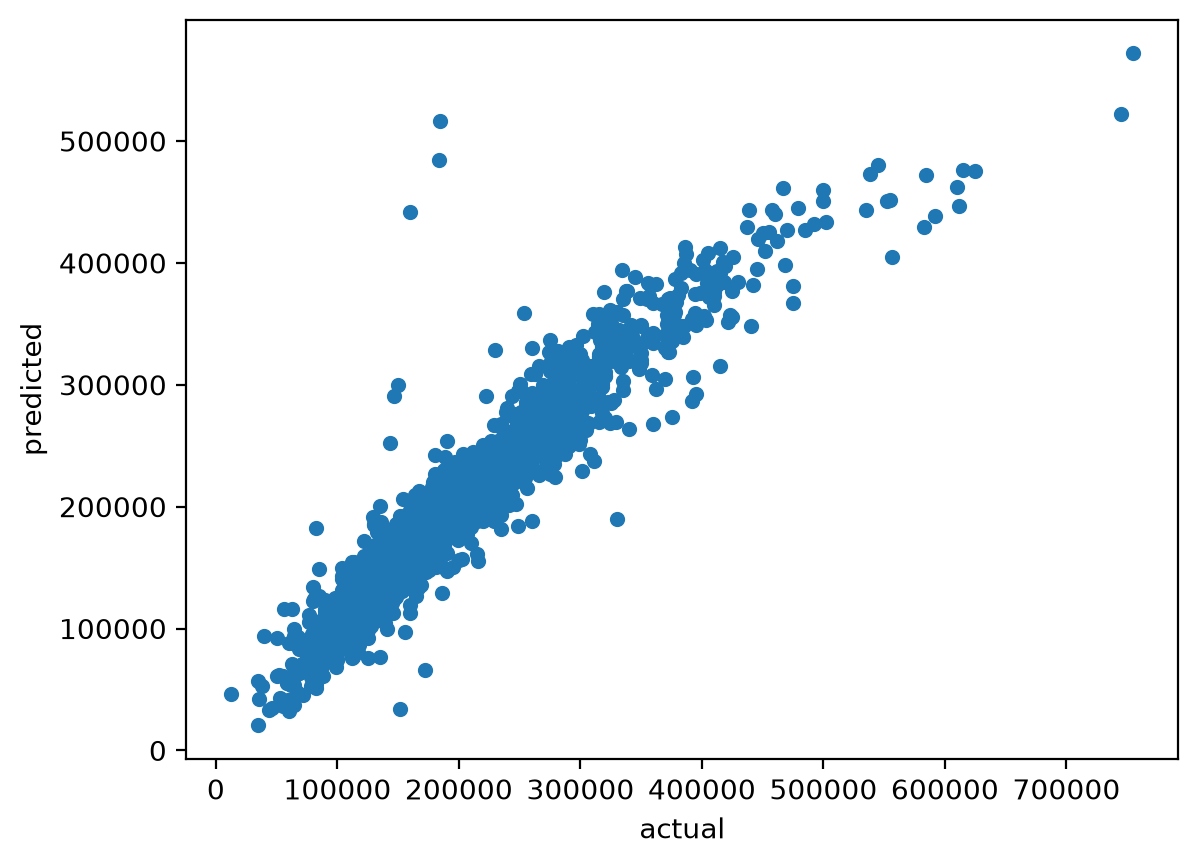

In [47]:
target.plot.scatter(x = "actual", y = "predicted")

## Practice Activity

## Loans Data

The loans data set represents thousands of loans made through the Lending Club platform, which is a platform that allows individuals to lend to other individuals. Of course, not all loans are created equal. Someone who is a essentially a sure bet to pay back a loan will have an easier time getting a loan with a low interest rate than someone who appears to be riskier. And for people who are very risky? They may not even get a loan offer, or they may not have accepted the loan offer due to a high interest rate. It is important to keep that last part in mind, since this dataset only represents loans actually made, i.e. do not mistake this data for loan applications!

[Some information about the data set is here](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). There are also some related exercises in this [OpenIntro textbook](https://openintro-ims.netlify.app/inf-model-mlr.html).

**Our goal will be to develop a regression model for predicting `interest_rate`.**

We will have a competition to see who can come up with the model with the smallest test RMSE. Fit several models and try to find the smallest test RMSE. When you think you have a good one, share your model and its test RMSE. Then see what other people have done; can you do even better?

**Previously you considered selected subsets of features. Now you should try, Ridge, LASSO, and elastic net.**

You should use `GridSearchCV` to tune at least one parameter.

Note: you should do some exploration of the data first before you start fitting models.

In [48]:
df = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/loans_full_schema.csv")

df

,Unnamed: 0,emp_title,emp_length,state,homeownership,annual_income,verified_income,debt_to_income,annual_income_joint,verification_income_joint,...,sub_grade,issue_month,loan_status,initial_listing_status,disbursement_method,balance,paid_total,paid_principal,paid_interest,paid_late_fees
0,1,global config engineer,3.0,NJ,MORTGAGE,90000.0,Verified,18.01,NaN,NaN,...,C3,Mar-2018,Current,whole,Cash,27015.86,1999.33,984.14,1015.19,0.0
1,2,warehouse office clerk,10.0,HI,RENT,40000.0,Not Verified,5.04,NaN,NaN,...,C1,Feb-2018,Current,whole,Cash,4651.37,499.12,348.63,150.49,0.0
2,3,assembly,3.0,WI,RENT,40000.0,Source Verified,21.15,NaN,NaN,...,D1,Feb-2018,Current,fractional,Cash,1824.63,281.80,175.37,106.43,0.0
3,4,customer service,1.0,PA,RENT,30000.0,Not Verified,10.16,NaN,NaN,...,A3,Jan-2018,Current,whole,Cash,18853.26,3312.89,2746.74,566.15,0.0
4,5,security supervisor,10.0,CA,RENT,35000.0,Verified,57.96,57000.0,Verified,...,C3,Mar-2018,Current,whole,Cash,21430.15,2324.65,1569.85,754.80,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,owner,10.0,TX,RENT,108000.0,Source Verified,22.28,NaN,NaN,...,A4,Jan-2018,Current,whole,Cash,21586.34,2969.80,2413.66,556.14,0.0
9996,9997,director,8.0,PA,MORTGAGE,121000.0,Verified,32.38,NaN,NaN,...,D3,Feb-2018,Current,whole,Cash,9147.44,1456.31,852.56,603.75,0.0
9997,9998,toolmaker,10.0,CT,MORTGAGE,67000.0,Verified,45.26,107000.0,Source Verified,...,E2,Feb-2018,Current,fractional,Cash,27617.65,4620.80,2382.35,2238.45,0.0
9998,9999,manager,1.0,WI,MORTGAGE,80000.0,Source Verified,11.99,NaN,NaN,...,A1,Feb-2018,Current,whole,Cash,21518.12,2873.31,2481.88,391.43,0.0


In [49]:
# Explore the target, missing values, and the number of levels in categorical variables.
print(f"{df.shape[0]:,} rows and {df.shape[1]} columns")
display(df["interest_rate"].describe().to_frame())

missing = (
    df.isna().sum()
    .sort_values(ascending=False)
    .rename("missing values")
    .to_frame()
)
display(missing.head(12))

categorical_levels = (
    df.select_dtypes(include=object).nunique()
    .sort_values(ascending=False)
    .rename("number of levels")
    .to_frame()
)
display(categorical_levels)

numeric_correlations = (
    df.select_dtypes(include=np.number)
    .corr()["interest_rate"]
    .drop("interest_rate")
    .abs()
    .sort_values(ascending=False)
    .rename("absolute correlation with interest_rate")
    .to_frame()
)
display(numeric_correlations.head(12))

10,000 rows and 56 columns


,interest_rate
count,10000.000000
mean,12.427524
std,5.001105
min,5.310000
25%,9.430000
50%,11.980000
75%,15.050000
max,30.940000


,missing values
verification_income_joint,8545
annual_income_joint,8505
debt_to_income_joint,8505
months_since_90d_late,7715
months_since_last_delinq,5658
months_since_last_credit_inquiry,1271
emp_title,833
emp_length,817
num_accounts_120d_past_due,318
debt_to_income,24


,number of levels
emp_title,4741
state,50
sub_grade,32
loan_purpose,12
grade,7
loan_status,6
homeownership,3
verified_income,3
verification_income_joint,3
issue_month,3


,absolute correlation with interest_rate
paid_interest,0.514508
term,0.358664
debt_to_income_joint,0.266417
total_debit_limit,0.254225
annual_income_joint,0.165327
debt_to_income,0.141653
num_mort_accounts,0.138351
inquiries_last_12m,0.131193
total_credit_limit,0.130497
account_never_delinq_percent,0.124702


The exploration reveals several variables that should not be used to predict the rate of a new loan. `grade`, `sub_grade`, and `installment` are assigned using the loan's interest rate, while `loan_status`, balance, and payment variables are only observed after origination. Including them would leak the answer into the predictors. The row number is also not a meaningful predictor. I exclude these variables below, but retain the other application and credit-history variables.

I first set aside 20% of the rows as a final test set. All preprocessing and tuning are then performed on the training rows only.

In [52]:
from sklearn.impute import SimpleImputer
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, train_test_split

leakage_columns = [
    "Unnamed: 0", "installment", "grade", "sub_grade",
    "loan_status", "balance", "paid_total", "paid_principal",
    "paid_interest", "paid_late_fees"
]

X_loans = df.drop(columns=["interest_rate"] + leakage_columns)
y_loans = df["interest_rate"]

X_train, X_test, y_train, y_test = train_test_split(
    X_loans, y_loans, test_size=0.20, random_state=5544
)

print("training set:", X_train.shape)
print("test set:    ", X_test.shape)

training set: (8000, 45)
test set:     (2000, 45)


In [53]:
# Put imputation, scaling, and dummification inside the pipeline so that
# each cross-validation fold learns its preprocessing from its training rows only.
numeric_features = X_train.select_dtypes(include=np.number).columns
categorical_features = X_train.select_dtypes(exclude=np.number).columns

numeric_preprocessing = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("standardize", StandardScaler())
])

categorical_preprocessing = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("dummify", OneHotEncoder(handle_unknown="ignore"))
])

loans_preprocessing = ColumnTransformer([
    ("numeric", numeric_preprocessing, numeric_features),
    ("categorical", categorical_preprocessing, categorical_features)
])

folds = KFold(n_splits=5, shuffle=True, random_state=5544)

Fit ridge, LASSO, and elastic net on the same five folds. The candidate `alpha` values differ because scikit-learn scales the penalties differently for these estimators. For elastic net, tune both `alpha` and `l1_ratio`.

In [54]:
model_searches = {
    "Ridge": (
        Ridge(),
        {"model__alpha": np.logspace(-2, 4, 7)}
    ),
    "LASSO": (
        Lasso(max_iter=20000),
        {"model__alpha": np.logspace(-3, 0, 7)}
    ),
    "Elastic net": (
        ElasticNet(max_iter=20000),
        {
            "model__alpha": np.logspace(-3, 0, 5),
            "model__l1_ratio": [0.1, 0.5, 0.9]
        }
    )
}

searches = {}
rows = []

for name, (model, param_grid) in model_searches.items():
    pipeline = Pipeline([
        ("preprocessing", loans_preprocessing),
        ("model", model)
    ])

    search = GridSearchCV(
        pipeline,
        param_grid=param_grid,
        cv=folds,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    search.fit(X_train, y_train)
    searches[name] = search
    rows.append({
        "model": name,
        "best parameters": search.best_params_,
        "CV RMSE": -search.best_score_
    })

cv_results = pd.DataFrame(rows).sort_values("CV RMSE", ignore_index=True)
cv_results

,model,best parameters,CV RMSE
0,Elastic net,"{'model__alpha': 0.005623413251903491, 'model_...",3.855925
1,LASSO,{'model__alpha': 0.01},3.857168
2,Ridge,{'model__alpha': 100.0},3.858533


selected model: Elastic net
best parameters: {'model__alpha': np.float64(0.005623413251903491), 'model__l1_ratio': 0.9}
CV RMSE:   3.856 percentage points
test RMSE: 3.961 percentage points


<Axes: title={'center': 'Elastic net: held-out predictions'}, xlabel='actual', ylabel='predicted'>

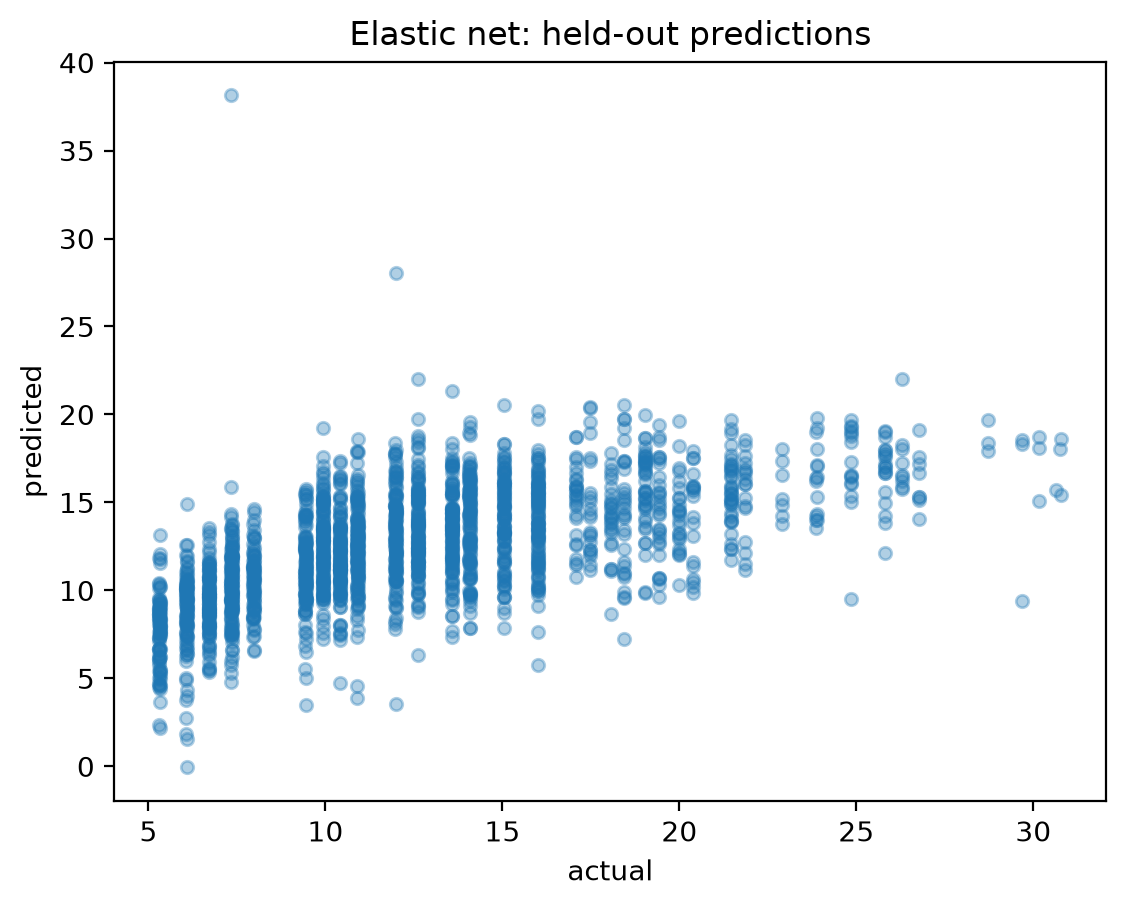

In [55]:
# Select the model family using CV only; use the held-out test set once.
winner_name = cv_results.loc[0, "model"]
winner = searches[winner_name]
test_predictions = winner.predict(X_test)
test_rmse = root_mean_squared_error(y_test, test_predictions)

print("selected model:", winner_name)
print("best parameters:", winner.best_params_)
print(f"CV RMSE:   {-winner.best_score_:.3f} percentage points")
print(f"test RMSE: {test_rmse:.3f} percentage points")

prediction_comparison = pd.DataFrame({
    "actual": y_test,
    "predicted": test_predictions
})
prediction_comparison.plot.scatter(
    x="actual", y="predicted", alpha=0.35,
    title=f"{winner_name}: held-out predictions"
)

In [56]:
# Inspect which transformed predictors the selected penalized model retained.
feature_names = (
    winner.best_estimator_
    .named_steps["preprocessing"]
    .get_feature_names_out()
)
coefficients = (
    pd.DataFrame({
        "feature": feature_names,
        "coefficient": winner.best_estimator_.named_steps["model"].coef_
    })
    .assign(abs_coefficient=lambda x: x["coefficient"].abs())
    .sort_values("abs_coefficient", ascending=False)
)

print("zero coefficients:", (coefficients["coefficient"] == 0).sum())
coefficients.head(20)

zero coefficients: 4013


,feature,coefficient,abs_coefficient
34,numeric__term,1.983587,1.983587
4080,categorical__disbursement_method_Cash,1.468769,1.468769
4081,categorical__disbursement_method_DirectPay,-1.468725,1.468725
4057,categorical__verified_income_Verified,1.358316,1.358316
4060,categorical__verification_income_joint_Verified,-1.204673,1.204673
28,numeric__num_cc_carrying_balance,1.055727,1.055727
4078,categorical__initial_listing_status_fractional,1.042011,1.042011
4079,categorical__initial_listing_status_whole,-1.028499,1.028499
25,numeric__total_debit_limit,-0.947310,0.947310
4055,categorical__verified_income_Not Verified,-0.755173,0.755173


### Result

With `random_state=5544`, the validated run selected **elastic net** with `alpha` about **0.00562** and `l1_ratio=0.9`. Its five-fold CV RMSE was about **3.856 percentage points**, and its final held-out test RMSE was about **3.961 percentage points**. Ridge and LASSO were very close in CV, so there is little evidence that one of the three model families is decisively better on these leakage-safe predictors.